In [1]:
import socket, os

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

WORKING_DIR = f"{BASE_DIR}/analysis/01_axis_analysis/bh/axis_sample_scores"
os.chdir(WORKING_DIR)
print(f"📂 Working directory set to: {WORKING_DIR}")

📂 Working directory set to: /Users/karenshih/Documents/research/scg/protein-master/v2_pancan_batch_corrected/analysis/01_axis_analysis/bh/axis_sample_scores


In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy.stats import pearsonr
from statsmodels.stats.multitest import fdrcorrection

mpl.rcParams["pdf.fonttype"] = 42

In [3]:
# ── PQC complexes ────────────────────────────────────────────────────────────
complex_scores_pqc = pd.read_csv(f"{BASE_DIR}/analysis/03_complex/complex_axis_score.csv")
df_long_pqc = complex_scores_pqc.drop(columns=["tmb_bin"]).melt(
    id_vars=["barcode", "cancer_type", "log_mut", "purity"],
    var_name="complex",
    value_name="score",
)

# ── non-PQC complexes ────────────────────────────────────────────────────────
NON_PQC_COMPLEXES = [
    "ribosome_biogenesis_in_eukaryotes",
    "spliceosome",
    "dna_replication",
    "cell_cycle",
    "oxidative_phosphorylation",
    "antigen_processing_and_presentation",
]

complex_scores_non_pqc = pd.read_csv(f"{BASE_DIR}/analysis/03_complex/complex_axis_score_non_pqc.csv")
df_long_non_pqc = complex_scores_non_pqc.melt(
    id_vars=["cancer_type", "log_mut", "barcode"],
    value_vars=NON_PQC_COMPLEXES,
    var_name="complex",
    value_name="score",
)

In [4]:
def bootstrap_global_corr(df_long, n_boot=1000, seed=2026):
    np.random.seed(seed)
    results = []

    for complex_name, df_c in df_long.groupby("complex"):
        df_c = df_c.dropna(subset=["score", "log_mut"])
        r_obs = pearsonr(df_c["score"], df_c["log_mut"])[0]

        cancer_types = df_c["cancer_type"].unique()
        n_cancer = len(cancer_types)
        groups = {ct: df_c[df_c["cancer_type"] == ct] for ct in cancer_types}

        boot_rs = []
        for _ in range(n_boot):
            sampled_types = np.random.choice(cancer_types, size=n_cancer, replace=True)
            df_boot = pd.concat([groups[ct] for ct in sampled_types])
            try:
                boot_rs.append(pearsonr(df_boot["score"], df_boot["log_mut"])[0])
            except Exception:
                continue

        boot_rs = np.array(boot_rs)
        ci_low  = np.percentile(boot_rs, 2.5)
        ci_high = np.percentile(boot_rs, 97.5)
        n = len(boot_rs)
        p_boot = 2 * min(
            (np.sum(boot_rs <= 0) + 1) / (n + 1),
            (np.sum(boot_rs >  0) + 1) / (n + 1),
        )

        results.append({
            "complex":   complex_name,
            "r":         r_obs,
            "ci_low":    ci_low,
            "ci_high":   ci_high,
            "p_boot":    p_boot,
            "n_samples": len(df_c),
        })

    result_df = pd.DataFrame(results)
    _, result_df["fdr"] = fdrcorrection(result_df["p_boot"])
    return result_df

In [5]:
global_corr_pqc     = bootstrap_global_corr(df_long_pqc,     n_boot=1000)
global_corr_non_pqc = bootstrap_global_corr(df_long_non_pqc, n_boot=1000)

global_corr_pqc["category"]     = "PQC"
global_corr_non_pqc["category"] = "non-PQC"

NAME_MAP = {
    "cell_cycle":                         "Cell cycle",
    "dna_replication":                    "DNA replication",
    "ribosome_biogenesis_in_eukaryotes":  "Ribosome biogenesis in eukaryotes",
    "spliceosome":                        "Spliceosome",
    "antigen_processing_and_presentation":"Antigen processing and presentation",
    "oxidative_phosphorylation":          "Oxidative phosphorylation",
}
global_corr_non_pqc["complex"] = global_corr_non_pqc["complex"].map(NAME_MAP)

global_corr_df  = pd.concat([global_corr_pqc, global_corr_non_pqc])
corr_df_sorted  = global_corr_df.sort_values(by=["category", "r"], ascending=[False, True])

# global_corr_df.to_csv(f"{BASE_DIR}/results/tables/fig1/cancer_type_bootstrap_pathway_tmb_corr.csv", index=False)

In [7]:
global_corr_df = pd.read_csv(f"{BASE_DIR}/results/tables/fig1/cancer_type_bootstrap_pathway_tmb_corr.csv")
corr_df_sorted  = global_corr_df.sort_values(by=["category", "r"], ascending=[False, True])

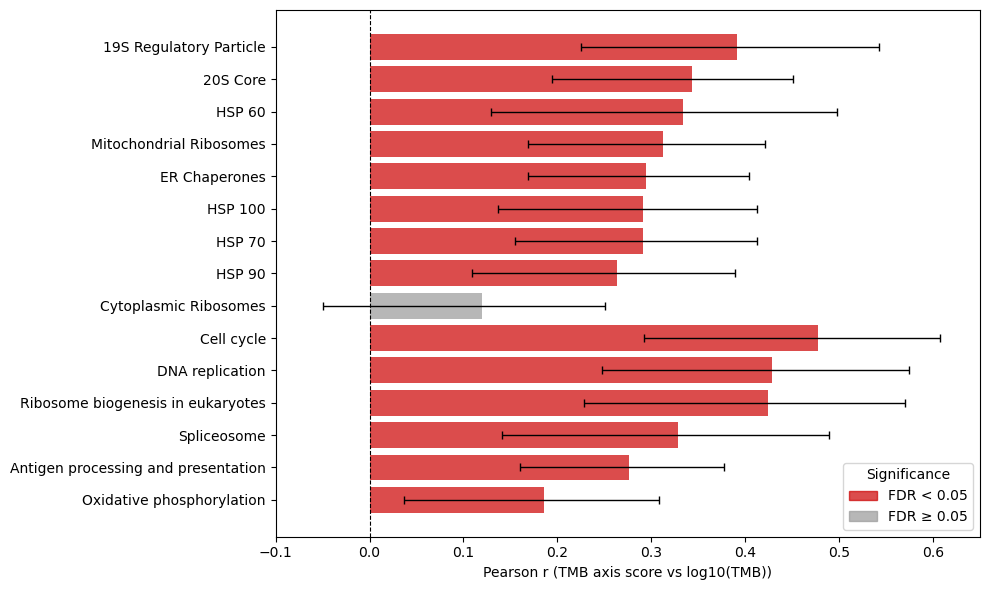

In [11]:
# ── Figure settings ──────────────────────────────────────────────────────────
FIG_SIZE  = (10, 6)
COLOR_SIG = "#CC0000"
COLOR_NS  = "#999999"
ALPHA     = 0.7
OUT_PATH  = f"{BASE_DIR}/results/figures/main/fig1/fig1d_pathway_tmb_corr_bs_types.pdf"

# ── Plot ─────────────────────────────────────────────────────────────────────
colors = [COLOR_SIG if p < 0.05 else COLOR_NS for p in corr_df_sorted["fdr"]]

fig, ax = plt.subplots(figsize=FIG_SIZE)

ax.barh(corr_df_sorted["complex"], corr_df_sorted["r"], color=colors, alpha=ALPHA)
ax.errorbar(
    x=corr_df_sorted["r"],
    y=corr_df_sorted["complex"],
    xerr=[
        corr_df_sorted["r"] - corr_df_sorted["ci_low"],
        corr_df_sorted["ci_high"] - corr_df_sorted["r"],
    ],
    fmt="none",
    color="black",
    capsize=3,
    linewidth=1,
)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_xlim(-0.1, 0.65)
ax.set_xlabel("Pearson r (TMB axis score vs log10(TMB))")

legend_handles = [
    mpatches.Patch(color=COLOR_SIG, alpha=ALPHA, label="FDR < 0.05"),
    mpatches.Patch(color=COLOR_NS,  alpha=ALPHA, label="FDR ≥ 0.05"),
]
ax.legend(handles=legend_handles, title="Significance", loc="lower right")

plt.tight_layout()
plt.savefig(OUT_PATH, dpi=300)
plt.show()